In [63]:
# imports
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box
from pathlib import Path

import nomad.io.base as loader
import nomad.data as data_folder
import nomad.filters as filters

import nomad.stop_detection.lachesis as LACHESIS
import nomad.stop_detection.density_based as SEQSCAN
import nomad.stop_detection.hdbscan as HDBSCAN
import nomad.stop_detection.dbscan as DBSCAN
import nomad.stop_detection.grid_based as GRID_BASED
from nomad.stop_detection.viz import plot_hexagons, plot_pings
from nomad.stop_detection.viz import animate_stop_dashboard

In [16]:
from pathlib import Path
import os

print("cwd:", os.getcwd())

repo_root = Path("/Users/anoushkamenon/Desktop/nomad")
print("repo exists:", repo_root.exists())

print("examples exists:", (repo_root / "examples").exists())
print("gc_data_long exists:", (repo_root / "examples" / "gc_data_long").exists())

cwd: /Users/anoushkamenon/Desktop
repo exists: True
examples exists: True
gc_data_long exists: True


### Lachesis

In [18]:
# load lachesis sample data & generate traj
data_dir = Path(data_folder.__file__).parent
city = gpd.read_parquet(data_dir / 'garden-city-buildings-mercator.parquet')
outer_box = box(*city.total_bounds)

filepath_root = str(repo_root / "examples" / "gc_data_long")
tc = {
    "user_id": "gc_identifier",
    "x": "dev_x",
    "y": "dev_y",
    "timestamp": "unix_ts"
}

users = ['admiring_brattain']

traj = loader.sample_from_file(
    filepath_root,
    format='parquet',
    users=users,
    filters=('date', '==', '2024-01-01'),
    traj_cols=tc
)

print(traj.head())
print(traj.columns)
print(len(traj))

       gc_identifier         dev_x         dev_y     unix_ts         ha  \
0  admiring_brattain -4.265481e+06  4.393146e+06  1704106881  10.702426   
1  admiring_brattain -4.265533e+06  4.393159e+06  1704107003  19.015804   
2  admiring_brattain -4.265477e+06  4.393185e+06  1704107072  24.851835   
3  admiring_brattain -4.265490e+06  4.393156e+06  1704107268  10.181171   
4  admiring_brattain -4.265491e+06  4.393147e+06  1704107349  11.100491   

   tz_offset        date  
0     -14400  2024-01-01  
1     -14400  2024-01-01  
2     -14400  2024-01-01  
3     -14400  2024-01-01  
4     -14400  2024-01-01  
Index(['gc_identifier', 'dev_x', 'dev_y', 'unix_ts', 'ha', 'tz_offset',
       'date'],
      dtype='str')
96


In [19]:
# generate stops
stops = LACHESIS.lachesis(
    traj,
    delta_roam=20,
    dt_max=60,
    dur_min=5,
    complete_output=True,
    keep_col_names=True,
    traj_cols=tc
)

print(stops.head())
print(stops.columns)
print(len(stops))

   cluster             x             y     unix_ts         ha   diameter  \
0        0 -4.265482e+06  4.393153e+06  1704107777  11.006086  14.820705   
1        1 -4.265478e+06  4.393120e+06  1704112028  11.038392  16.458197   
2        2 -4.265482e+06  4.393117e+06  1704112843  12.200451  18.663269   
3        3 -4.265475e+06  4.393110e+06  1704113482   9.792796   8.638411   
4        4 -4.265449e+06  4.393130e+06  1704114942  11.163325  17.188732   

   n_pings  end_timestamp  duration  max_gap      gc_identifier  
0        3     1704108899        18       12  admiring_brattain  
1        6     1704112657        10        3  admiring_brattain  
2        4     1704113143         5        3  admiring_brattain  
3        3     1704113875         6        6  admiring_brattain  
4        6     1704116038        18        7  admiring_brattain  
Index(['cluster', 'x', 'y', 'unix_ts', 'ha', 'diameter', 'n_pings',
       'end_timestamp', 'duration', 'max_gap', 'gc_identifier'],
      dtype='s

In [21]:
# fix timestamp to match anim func
stops_anim = stops.rename(columns={'unix_ts': 'timestamp'}).copy()
traj_anim = traj.rename(columns={'unix_ts': 'timestamp'}).copy()

tc_anim = {
    "user_id": "gc_identifier",
    "x": "dev_x",
    "y": "dev_y",
    "timestamp": "timestamp"
}

In [22]:
%%capture

# run it & save GIF locally
anim_lach = animate_stop_dashboard(
    data=traj_anim,
    stops=stops_anim,
    save_path="lachesis_test.gif",
    traj_cols=tc_anim,
    show_path=True,
    base_geometry=city,
    base_geom_color="#ebebeb",
    base_geom_background="white"
)

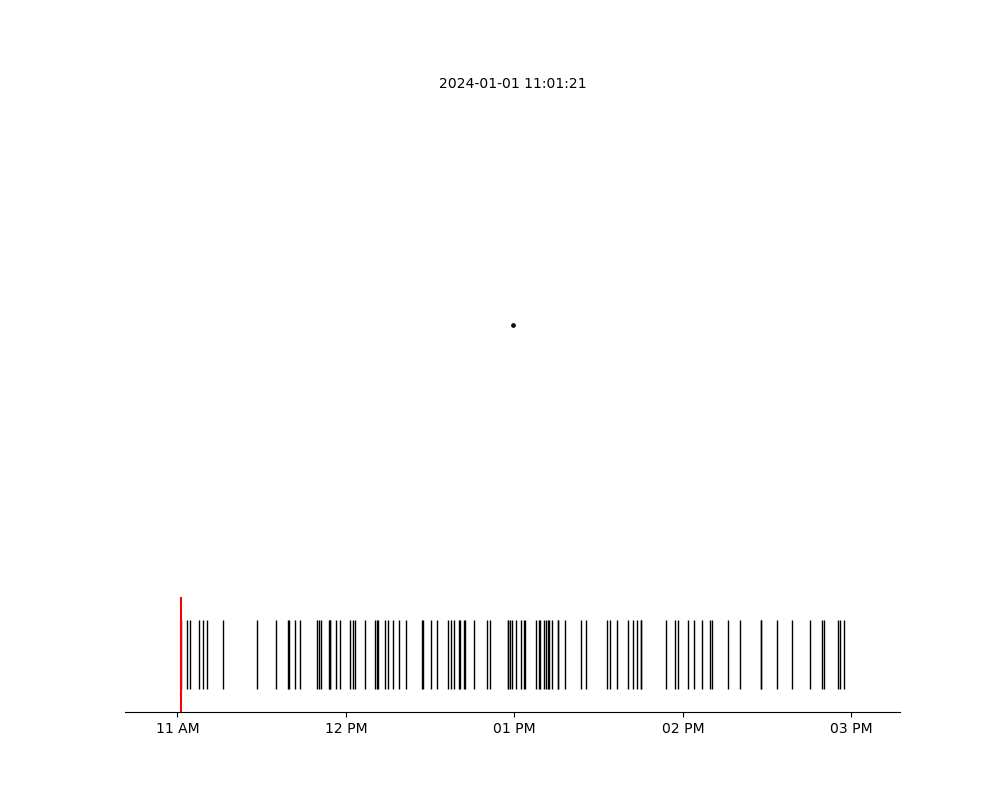

In [23]:
from IPython.display import Image
Image(filename="lachesis_test.gif")

### SeqScan

In [24]:
stops_seqscan = SEQSCAN.seqscan(
    traj,
    time_thresh=60,
    dist_thresh=8,
    min_pts=3,
    complete_output=True,
    traj_cols=tc
)

print(stops_seqscan.head())
print(stops_seqscan.columns.tolist())
print(len(stops_seqscan))

   cluster             x             y     unix_ts         ha   diameter  \
0        0 -4.265483e+06  4.393152e+06  1704107268  15.428344  17.490164   
1        1 -4.265479e+06  4.393109e+06  1704110542  10.904197  22.963333   
2        2 -4.265444e+06  4.393141e+06  1704114212  11.838617  30.268388   
3        3 -4.265442e+06  4.393104e+06  1704118232  12.179614  21.014442   

   n_pings  end_timestamp  duration  max_gap      gc_identifier  
0        6     1704109867        43       17  admiring_brattain  
1       14     1704114036        58       15  admiring_brattain  
2       12     1704117441        53        9  admiring_brattain  
3        8     1704121040        46       21  admiring_brattain  
['cluster', 'x', 'y', 'unix_ts', 'ha', 'diameter', 'n_pings', 'end_timestamp', 'duration', 'max_gap', 'gc_identifier']
4


In [25]:
traj_anim = traj.rename(columns={'unix_ts': 'timestamp'}).copy()
stops_seqscan_anim = stops_seqscan.rename(columns={'unix_ts': 'timestamp'}).copy()

tc_anim = {
    "user_id": "gc_identifier",
    "x": "dev_x",
    "y": "dev_y",
    "timestamp": "timestamp"
}

In [26]:
%%capture
anim_seq = animate_stop_dashboard(
    data=traj_anim,
    stops=stops_seqscan_anim,
    save_path="seqscan_test.gif",
    traj_cols=tc_anim,
    show_path=True,
    base_geometry=city,
    base_geom_color="#ebebeb",
    base_geom_background="white"
)

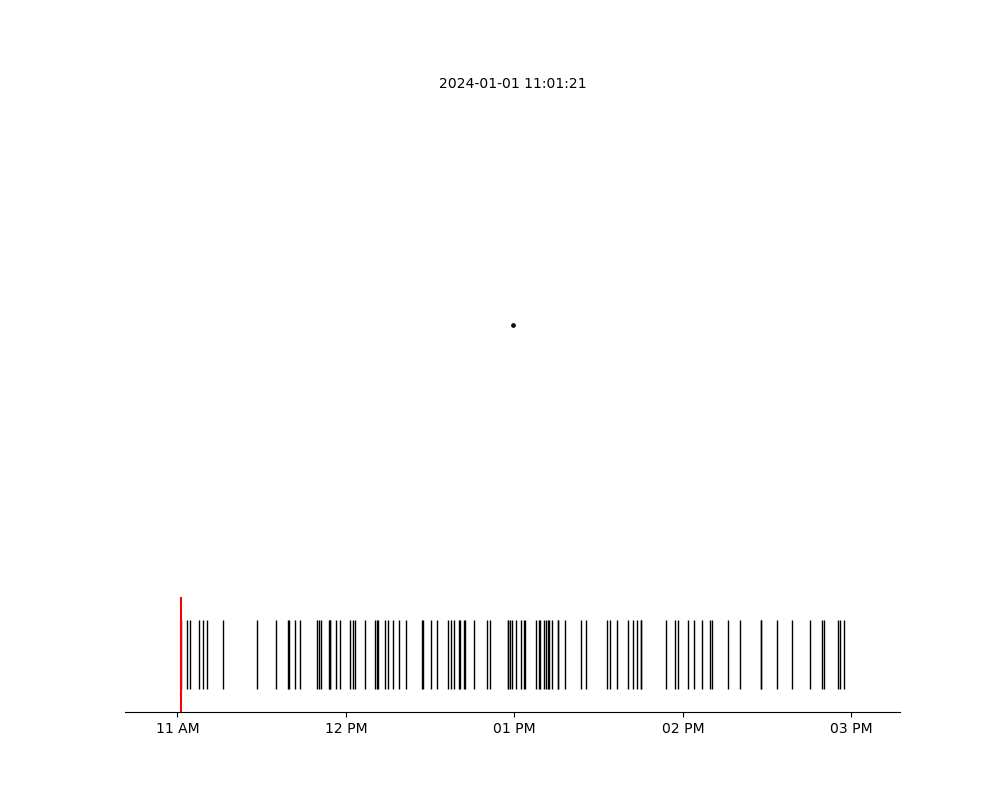

In [27]:
from IPython.display import Image
Image(filename="seqscan_test.gif")

### HDBSCAN

In [58]:
stops_hdb = HDBSCAN.st_hdbscan(
    traj,
    time_thresh=720,
    min_pts=3,
    complete_output=True,
    traj_cols=tc
)

print(stops_hdb.head())
print(stops_hdb.columns.tolist())
print(len(stops_hdb))

   cluster             x             y     unix_ts         ha   diameter  \
0        0 -4.265481e+06  4.393146e+06  1704106881  11.525814  30.802809   
1        1 -4.265486e+06  4.393141e+06  1704110051  10.189959  34.652360   
2        2 -4.265482e+06  4.393117e+06  1704111064  12.335014  34.995701   
3        3 -4.265476e+06  4.393116e+06  1704113482   9.867250  23.089836   
4        4 -4.265447e+06  4.393139e+06  1704114212  11.471560  25.793540   

   n_pings  end_timestamp  duration  max_gap      gc_identifier  
0       11     1704109867        49       17  admiring_brattain  
1        5     1704110595         9        5  admiring_brattain  
2       16     1704113143        34        8  admiring_brattain  
3        6     1704114036         9        6  admiring_brattain  
4       15     1704116038        30        7  admiring_brattain  
['cluster', 'x', 'y', 'unix_ts', 'ha', 'diameter', 'n_pings', 'end_timestamp', 'duration', 'max_gap', 'gc_identifier']
6


In [59]:
stops_hdb = HDBSCAN.st_hdbscan(
    traj,
    time_thresh=720,
    min_pts=3,
    complete_output=True,
    traj_cols=tc
)

print(stops_hdb.head())
print(stops_hdb.columns.tolist())
print(len(stops_hdb))

   cluster             x             y     unix_ts         ha   diameter  \
0        0 -4.265481e+06  4.393146e+06  1704106881  11.525814  30.802809   
1        1 -4.265486e+06  4.393141e+06  1704110051  10.189959  34.652360   
2        2 -4.265482e+06  4.393117e+06  1704111064  12.335014  34.995701   
3        3 -4.265476e+06  4.393116e+06  1704113482   9.867250  23.089836   
4        4 -4.265447e+06  4.393139e+06  1704114212  11.471560  25.793540   

   n_pings  end_timestamp  duration  max_gap      gc_identifier  
0       11     1704109867        49       17  admiring_brattain  
1        5     1704110595         9        5  admiring_brattain  
2       16     1704113143        34        8  admiring_brattain  
3        6     1704114036         9        6  admiring_brattain  
4       15     1704116038        30        7  admiring_brattain  
['cluster', 'x', 'y', 'unix_ts', 'ha', 'diameter', 'n_pings', 'end_timestamp', 'duration', 'max_gap', 'gc_identifier']
6


In [60]:
traj_anim = traj.rename(columns={'unix_ts': 'timestamp'}).copy()
stops_hdb_anim = stops_hdb.rename(columns={'unix_ts': 'timestamp'}).copy()

tc_anim = {
    "user_id": "gc_identifier",
    "x": "dev_x",
    "y": "dev_y",
    "timestamp": "timestamp"
}

In [61]:
%%capture
anim_hdb = animate_stop_dashboard(
    data=traj_anim,
    stops=stops_hdb_anim,
    save_path="hdbscan_test.gif",
    traj_cols=tc_anim,
    show_path=True,
    base_geometry=city,
    base_geom_color="#ebebeb",
    base_geom_background="white"
)

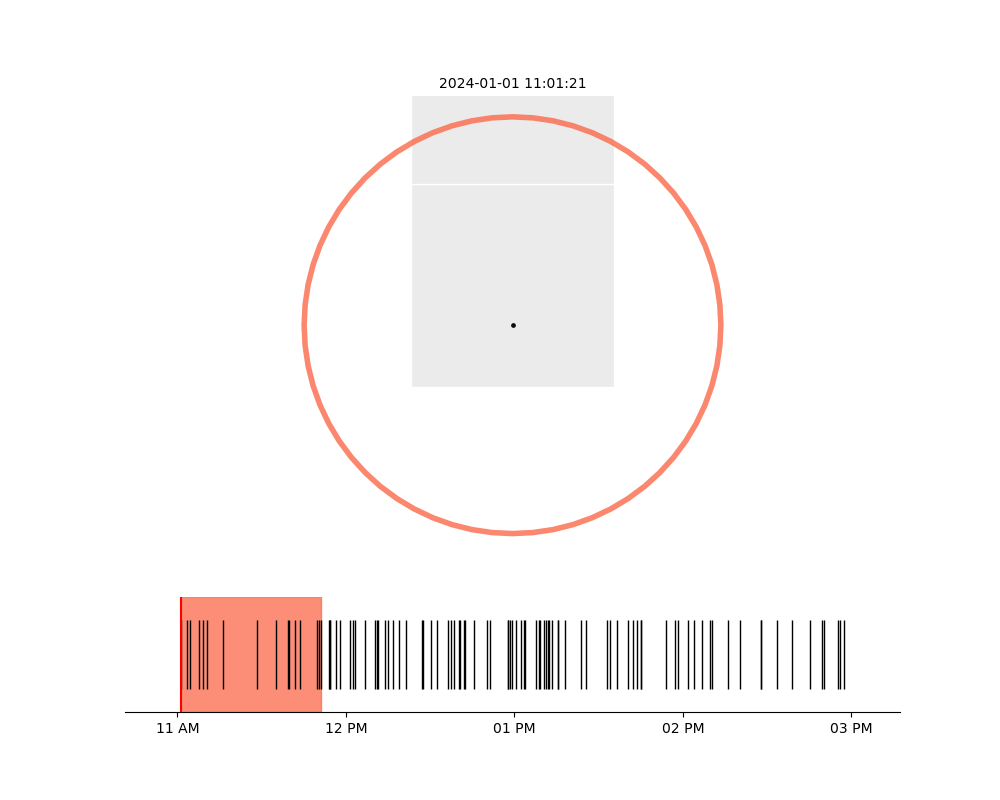

In [62]:
from IPython.display import Image
Image(filename="hdbscan_test.gif")

### TADBSCAN

In [64]:
stops_tadb = DBSCAN.ta_dbscan(
    traj,
    time_thresh=60,
    dist_thresh=10,
    min_pts=3,
    complete_output=True,
    traj_cols=tc
)

print(stops_tadb.head())
print(stops_tadb.columns.tolist())
print(len(stops_tadb))

   cluster             x             y     unix_ts         ha   diameter  \
0        0 -4.265481e+06  4.393146e+06  1704106881  12.063766  53.421270   
1        1 -4.265456e+06  4.393119e+06  1704111025  16.546921   0.000000   
2        2 -4.265482e+06  4.393117e+06  1704111064  12.412725  34.995701   
3        3 -4.265449e+06  4.393124e+06  1704113416  29.293973   0.000000   
4        4 -4.265476e+06  4.393116e+06  1704113482   9.867250  23.089836   

   n_pings  end_timestamp  duration  max_gap      gc_identifier  
0       18     1704110595        61       12  admiring_brattain  
1        1     1704111025         0        0  admiring_brattain  
2       17     1704113143        34        8  admiring_brattain  
3        1     1704113416         0        0  admiring_brattain  
4        6     1704114036         9        6  admiring_brattain  
['cluster', 'x', 'y', 'unix_ts', 'ha', 'diameter', 'n_pings', 'end_timestamp', 'duration', 'max_gap', 'gc_identifier']
6


In [65]:
traj_anim = traj.rename(columns={'unix_ts': 'timestamp'}).copy()
stops_tadb_anim = stops_tadb.rename(columns={'unix_ts': 'timestamp'}).copy()

tc_anim = {
    "user_id": "gc_identifier",
    "x": "dev_x",
    "y": "dev_y",
    "timestamp": "timestamp"
}

In [66]:
%%capture
anim_tadb = animate_stop_dashboard(
    data=traj_anim,
    stops=stops_tadb_anim,
    save_path="tadbscan_test.gif",
    traj_cols=tc_anim,
    show_path=True,
    base_geometry=city,
    base_geom_color="#ebebeb",
    base_geom_background="white"
)

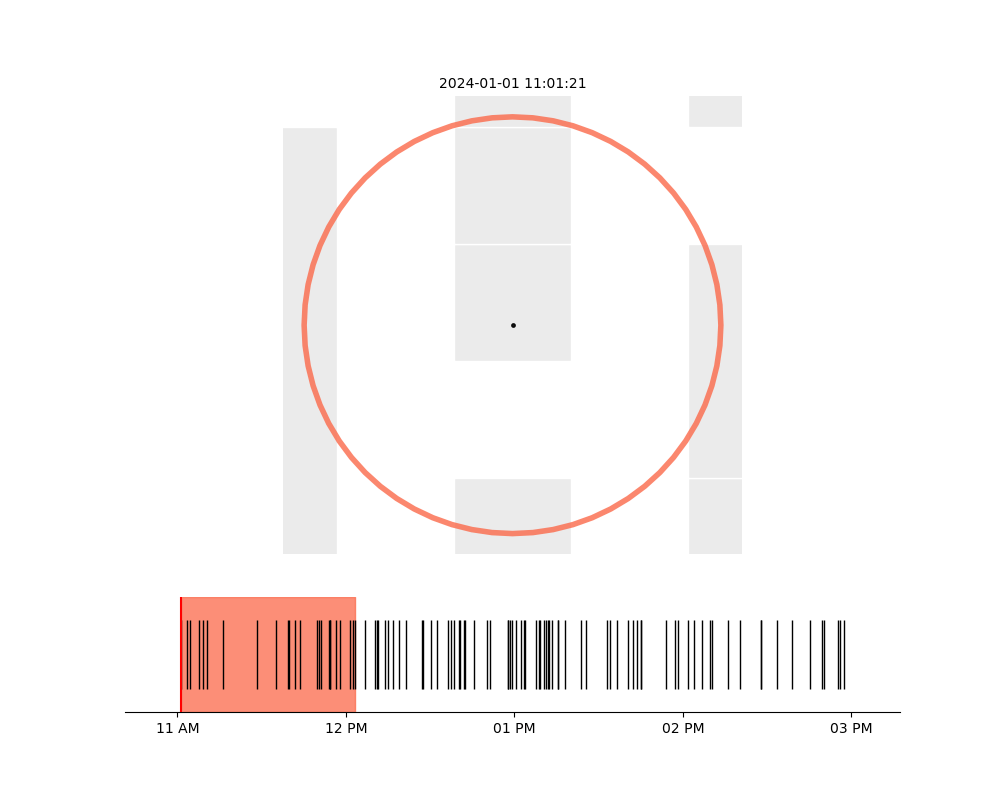

In [67]:
from IPython.display import Image
Image(filename="tadbscan_test.gif")

### Grid Based (in progress)

In [44]:
import importlib
import nomad.stop_detection.viz as viz

importlib.reload(viz)
from nomad.stop_detection.viz import animate_stop_dashboard

In [46]:
# create H3 tessellation column
traj_gb = traj.copy()
traj_gb['h3_cell'] = filters.to_tessellation(
    traj_gb,
    index="h3",
    res=11,
    traj_cols=tc,
    data_crs='EPSG:3857'
)

# run grid-based stop detection
stops_gb = GRID_BASED.grid_based(
    traj_gb,
    time_thresh=240,
    complete_output=True,
    location_id='h3_cell',
    traj_cols=tc
)

print(stops_gb.head())
print(stops_gb.columns.tolist())
print(len(stops_gb))

   cluster     unix_ts  duration  end_timestamp  n_pings  max_gap  \
0        0  1704107072        30     1704108899        7       12   
1        1  1704109180        11     1704109867        6        6   
2        2  1704110542         9     1704111089        6        3   
3        3  1704112028        18     1704113143       12        3   
4        4  1704113482         9     1704114036        6        6   

           h3_cell  
0  8b3593605ad1fff  
1  8b3593605ad1fff  
2  8b3593605adefff  
3  8b3593605adefff  
4  8b3593605adefff  
['cluster', 'unix_ts', 'duration', 'end_timestamp', 'n_pings', 'max_gap', 'h3_cell']
8


In [47]:
traj_gb_anim = traj_gb.rename(columns={'unix_ts': 'timestamp'}).copy()
stops_gb_anim = stops_gb.rename(columns={'unix_ts': 'timestamp'}).copy()

tc_gb_anim = {
    "user_id": "gc_identifier",
    "x": "dev_x",
    "y": "dev_y",
    "timestamp": "timestamp"
}

In [48]:
%%capture
anim_gb = animate_stop_dashboard(
    data=traj_gb_anim,
    stops=stops_gb_anim,
    save_path="grid_based_test.gif",
    traj_cols=tc_gb_anim,
    show_path=True,
    base_geometry=city,
    base_geom_color="#ebebeb",
    base_geom_background="white",
    data_crs="EPSG:3857"
)

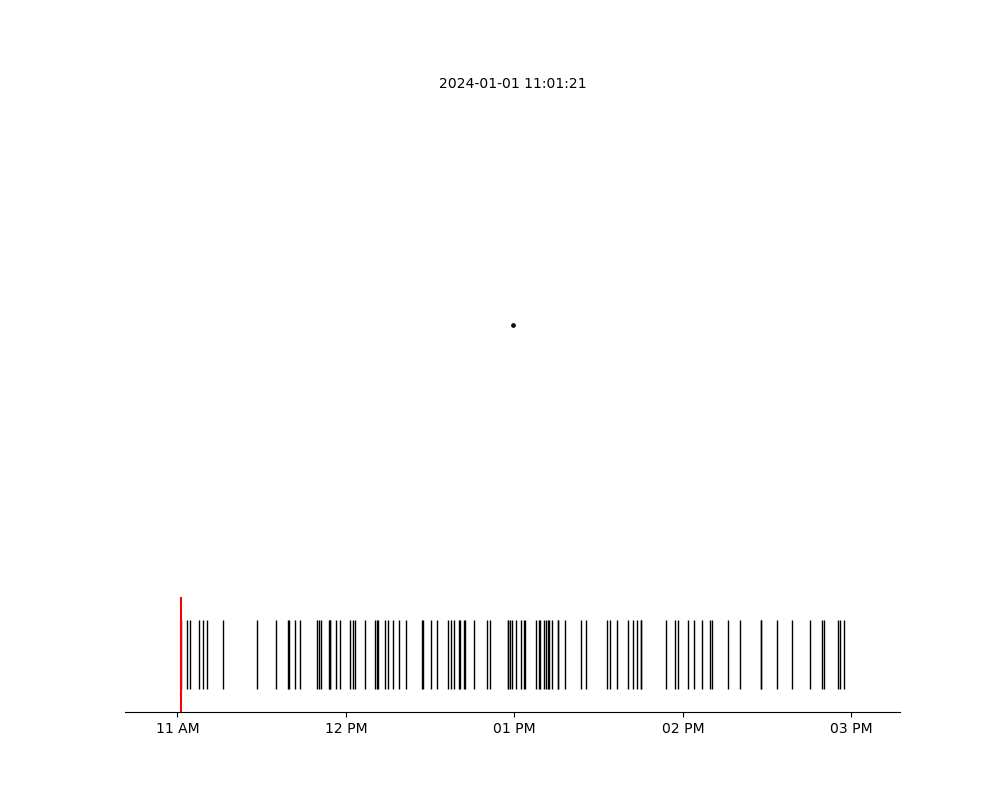

In [49]:
from IPython.display import Image
Image(filename="grid_based_test.gif")

##### Debugging GB

In [51]:
idx = len(traj_gb_anim) // 2  # middle frame

current_time = traj_gb_anim['timestamp'].iloc[idx]
stops_visible = stops_gb_anim[stops_gb_anim['timestamp'] <= current_time]

print(len(stops_visible))
print(stops_visible.head())

5
   cluster   timestamp  duration  end_timestamp  n_pings  max_gap  \
0        0  1704107072        30     1704108899        7       12   
1        1  1704109180        11     1704109867        6        6   
2        2  1704110542         9     1704111089        6        3   
3        3  1704112028        18     1704113143       12        3   
4        4  1704113482         9     1704114036        6        6   

           h3_cell  
0  8b3593605ad1fff  
1  8b3593605ad1fff  
2  8b3593605adefff  
3  8b3593605adefff  
4  8b3593605adefff  


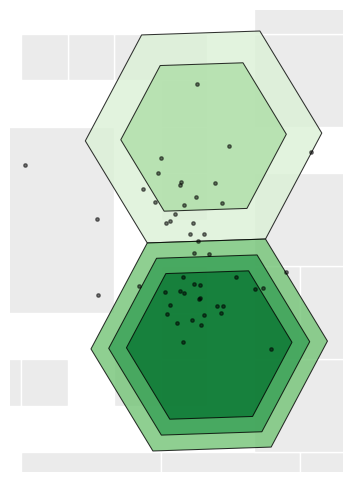

In [52]:
from nomad.stop_detection.viz import plot_hexagons, plot_pings
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

plot_pings(
    traj_gb_anim.iloc[:idx+1],
    ax=ax,
    s=6,
    color='black',
    alpha=0.5,
    traj_cols=tc_gb_anim,
    base_geometry=city,
    base_geom_color="#ebebeb",
    base_geom_background="white",
    data_crs="EPSG:3857"
)

plot_hexagons(
    stops_visible,
    ax=ax,
    color='cluster',
    cmap='Greens',
    data_crs='EPSG:3857',
    traj_cols={"location_id": "h3_cell"}
)

ax.set_axis_off()
plt.show()

In [53]:
print(len(stops_visible))

5
